# BatteryIQ — ANN SOH Prediction

**Member 4 — Advanced SOH Model**

This notebook implements the ANN SOH model under the frozen BatteryIQ ML contract.

- Target: `soh` in percentage points
- Predictors: exact frozen 15-feature set
- Validation: Leave-One-Battery-Out (LOGO)
- `battery_id` is used only for grouping and reporting
- `capacity` and target-derived information are never predictors
- Scaling is fitted separately inside every LOGO fold


In [9]:
from pathlib import Path
import sys
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "data").exists() and not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "data").exists():
    raise FileNotFoundError("Could not locate BatteryIQ repository root.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models.ann_soh import (
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    build_ann_soh,
    set_random_seed,
)

SEED = 42
set_random_seed(SEED)
print("Repository root:", ROOT)
print("TensorFlow:", tf.__version__)


Repository root: d:\VIT Academic\TY\sem 5\EDI\BatteryIQ
TensorFlow: 2.21.0


In [10]:
FEATURE_PATH = ROOT / "data/features/battery_cycle_features.csv"
TARGET_PATH = ROOT / "data/features/battery_cycle_targets.csv"

features = pd.read_csv(FEATURE_PATH)
targets = pd.read_csv(TARGET_PATH)

assert features.shape == (636, 17), f"Unexpected feature shape: {features.shape}"
assert targets.shape == (636, 4), f"Unexpected target shape: {targets.shape}"

assert features[["battery_id", "cycle"]].duplicated().sum() == 0
assert targets[["battery_id", "cycle"]].duplicated().sum() == 0

ml_df = features.merge(
    targets,
    on=["battery_id", "cycle"],
    how="inner",
    validate="one_to_one",
)

assert len(ml_df) == 636
assert ml_df[FEATURE_COLUMNS].isna().sum().sum() == 0
assert ml_df[TARGET_COLUMN].isna().sum() == 0

X = ml_df[FEATURE_COLUMNS].copy()
y = ml_df[TARGET_COLUMN].copy()
groups = ml_df["battery_id"].copy()

print("ML shape:", ml_df.shape)
print("Features:", X.columns.tolist())
print("Batteries:", groups.unique().tolist())


ML shape: (636, 19)
Features: ['voltage_mean', 'voltage_min', 'voltage_max', 'voltage_std', 'current_mean', 'current_min', 'current_max', 'temperature_mean', 'temperature_max', 'current_load_mean', 'voltage_load_mean', 'cycle_time', 'voltage_change', 'temperature_change', 'temperature_rolling_mean']
Batteries: ['B0005', 'B0006', 'B0007', 'B0018']


## ANN architecture

```text
15 frozen features
      ↓
Dense(64, ReLU)
      ↓
Dropout(0.20)
      ↓
Dense(32, ReLU)
      ↓
Dropout(0.10)
      ↓
Dense(16, ReLU)
      ↓
Dense(1, Linear)
      ↓
SOH (%)
```

Adam optimizer is used with MSE loss and MAE as a monitoring metric.


In [11]:
logo = LeaveOneGroupOut()
fold_results = []
all_predictions = []
histories = []

for fold, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
    test_battery = groups.iloc[test_idx].iloc[0]

    X_train_raw = X.iloc[train_idx]
    X_test_raw = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Feature scaling is fitted only on training batteries.
    x_scaler = StandardScaler()
    X_train = x_scaler.fit_transform(X_train_raw).astype(np.float32)
    X_test = x_scaler.transform(X_test_raw).astype(np.float32)

    # Target scaling improves neural-network optimization while preserving
    # the reported SOH values after inverse transformation.
    y_scaler = StandardScaler()
    y_train_scaled = y_scaler.fit_transform(
        y_train.to_numpy().reshape(-1, 1)
    ).reshape(-1).astype(np.float32)

    # Fresh network for every held-out battery.
    set_random_seed(SEED + fold)
    model = build_ann_soh(input_dim=X_train.shape[1], seed=SEED + fold)

    history = model.fit(
        X_train,
        y_train_scaled,
        epochs=500,
        batch_size=16,
        validation_split=0.15,
        shuffle=True,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=40,
                restore_best_weights=True,
                min_delta=1e-4,
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=15,
                min_lr=1e-5,
            ),
        ],
        verbose=0,
    )

    y_pred_scaled = model.predict(X_test, verbose=0).reshape(-1, 1)
    y_pred = y_scaler.inverse_transform(y_pred_scaled).reshape(-1)

    fold_results.append({
        "fold": fold,
        "test_battery": test_battery,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
        "epochs_run": len(history.history["loss"]),
    })

    all_predictions.append(pd.DataFrame({
        "battery_id": test_battery,
        "cycle": ml_df.iloc[test_idx]["cycle"].to_numpy(),
        "actual_soh": y_test.to_numpy(),
        "predicted_soh": y_pred,
    }))
    histories.append((test_battery, history))

fold_results_df = pd.DataFrame(fold_results)
predictions_df = pd.concat(all_predictions, ignore_index=True)

print(fold_results_df.to_string(index=False))


 fold test_battery      MAE     RMSE       R2  epochs_run
    1        B0005 1.430199 1.748282 0.966078         142
    2        B0006 3.748777 4.177371 0.889458         112
    3        B0007 2.899384 3.351835 0.825484         116
    4        B0018 2.308253 2.589140 0.887369         157


In [12]:
overall_mae = mean_absolute_error(
    predictions_df["actual_soh"], predictions_df["predicted_soh"]
)
overall_rmse = np.sqrt(mean_squared_error(
    predictions_df["actual_soh"], predictions_df["predicted_soh"]
))
overall_r2 = r2_score(
    predictions_df["actual_soh"], predictions_df["predicted_soh"]
)

print("\nOverall held-out predictions:")
print(f"MAE : {overall_mae:.4f}")
print(f"RMSE: {overall_rmse:.4f}")
print(f"R2  : {overall_r2:.4f}")

print("\nMean fold metrics:")
print(fold_results_df[["MAE", "RMSE", "R2"]].mean().to_string())



Overall held-out predictions:
MAE : 2.6130
RMSE: 3.1266
R2  : 0.9009

Mean fold metrics:
MAE     2.596653
RMSE    2.966657
R2      0.892097


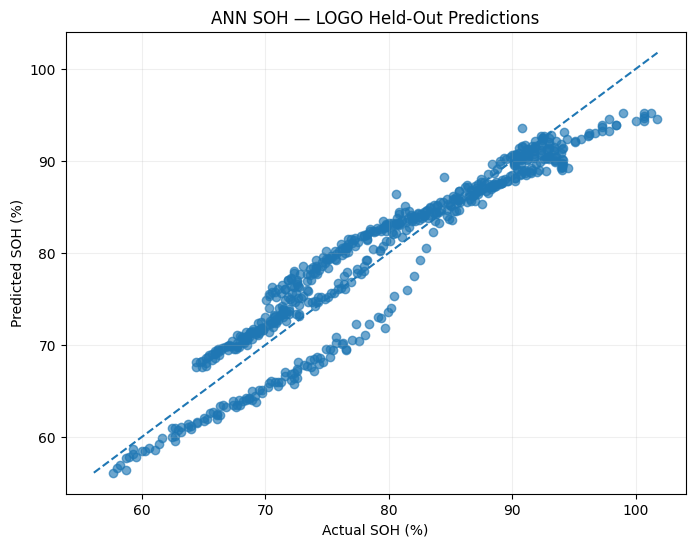

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(predictions_df["actual_soh"], predictions_df["predicted_soh"], alpha=0.65)
lims = [
    min(predictions_df["actual_soh"].min(), predictions_df["predicted_soh"].min()),
    max(predictions_df["actual_soh"].max(), predictions_df["predicted_soh"].max()),
]
ax.plot(lims, lims, linestyle="--")
ax.set_xlabel("Actual SOH (%)")
ax.set_ylabel("Predicted SOH (%)")
ax.set_title("ANN SOH — LOGO Held-Out Predictions")
ax.grid(True, alpha=0.2)
plt.show()


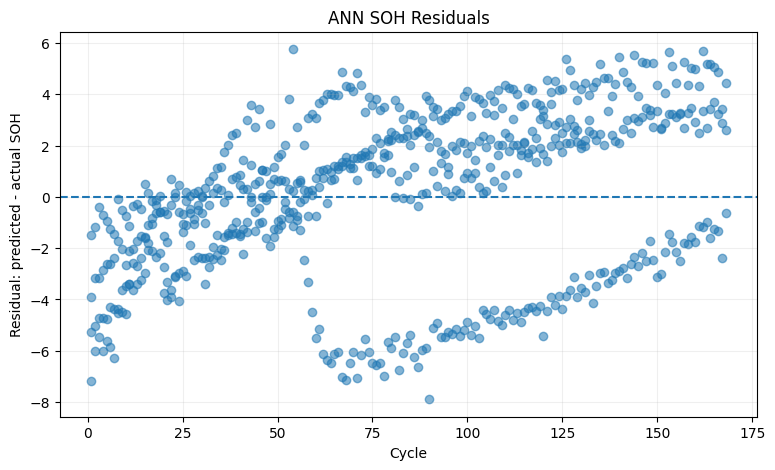

In [14]:
predictions_df["residual"] = (
    predictions_df["predicted_soh"] - predictions_df["actual_soh"]
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(0, linestyle="--")
ax.scatter(predictions_df["cycle"], predictions_df["residual"], alpha=0.55)
ax.set_xlabel("Cycle")
ax.set_ylabel("Residual: predicted - actual SOH")
ax.set_title("ANN SOH Residuals")
ax.grid(True, alpha=0.2)
plt.show()


## Final deployment artifact

LOGO is the evaluation experiment. After evaluation, a separate final model is trained on **all 636 frozen cycles** using the already-validated ANN architecture.

This final artifact is for inference only. It is not used to report the LOGO metrics above.


In [15]:
ARTIFACT_DIR = ROOT / "models/soh/ann"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Deployment preprocessing is fitted on all frozen training data only after
# LOGO evaluation has been completed.
final_x_scaler = StandardScaler()
X_all_scaled = final_x_scaler.fit_transform(X).astype(np.float32)

final_y_scaler = StandardScaler()
y_all_scaled = final_y_scaler.fit_transform(
    y.to_numpy().reshape(-1, 1)
).reshape(-1).astype(np.float32)

set_random_seed(SEED)
final_model = build_ann_soh(input_dim=X_all_scaled.shape[1], seed=SEED)

final_history = final_model.fit(
    X_all_scaled,
    y_all_scaled,
    epochs=500,
    batch_size=16,
    validation_split=0.15,
    shuffle=True,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=40,
            restore_best_weights=True,
            min_delta=1e-4,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=15,
            min_lr=1e-5,
        ),
    ],
    verbose=0,
)

model_path = ARTIFACT_DIR / "ann_soh.keras"
scaler_path = ARTIFACT_DIR / "scaler.joblib"
target_scaler_path = ARTIFACT_DIR / "target_scaler.joblib"
metadata_path = ARTIFACT_DIR / "metadata.json"

final_model.save(model_path)
joblib.dump(final_x_scaler, scaler_path)
joblib.dump(final_y_scaler, target_scaler_path)

metadata = {
    "model_name": "BatteryIQ_ANN_SOH",
    "target": TARGET_COLUMN,
    "features": FEATURE_COLUMNS,
    "random_seed": SEED,
    "architecture": [
        "Dense(64, relu)",
        "Dropout(0.20)",
        "Dense(32, relu)",
        "Dropout(0.10)",
        "Dense(16, relu)",
        "Dense(1, linear)",
    ],
    "optimizer": "Adam(learning_rate=0.001)",
    "loss": "MSE",
    "target_scaling": "StandardScaler fitted on training target inside each LOGO fold",
    "epochs_max": 500,
    "batch_size": 16,
    "early_stopping_patience": 40,
    "reduce_lr_on_plateau": True,
    "deployment_training_rows": int(len(X)),
    "validation_method": "Leave-One-Battery-Out (LOGO)",
    "eol_threshold_percent": 70.0,
}

metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved:")
print(model_path)
print(scaler_path)
print(target_scaler_path)
print(metadata_path)


Saved:
d:\VIT Academic\TY\sem 5\EDI\BatteryIQ\models\soh\ann\ann_soh.keras
d:\VIT Academic\TY\sem 5\EDI\BatteryIQ\models\soh\ann\scaler.joblib
d:\VIT Academic\TY\sem 5\EDI\BatteryIQ\models\soh\ann\target_scaler.joblib
d:\VIT Academic\TY\sem 5\EDI\BatteryIQ\models\soh\ann\metadata.json


In [16]:
# Artifact smoke test
loaded_model = tf.keras.models.load_model(ARTIFACT_DIR / "ann_soh.keras")
loaded_scaler = joblib.load(ARTIFACT_DIR / "scaler.joblib")
loaded_target_scaler = joblib.load(ARTIFACT_DIR / "target_scaler.joblib")

sample = X.iloc[[0]]
sample_scaled = loaded_scaler.transform(sample).astype(np.float32)
sample_prediction_scaled = loaded_model.predict(
    sample_scaled, verbose=0
).reshape(-1, 1)
sample_prediction = float(
    loaded_target_scaler.inverse_transform(sample_prediction_scaled).reshape(-1)[0]
)

assert np.isfinite(sample_prediction)
assert loaded_scaler.n_features_in_ == len(FEATURE_COLUMNS)

print("Smoke test passed.")
print("Sample predicted SOH:", round(sample_prediction, 4))


Smoke test passed.
Sample predicted SOH: 90.6316
